In [2]:
import pandas as pd
import numpy as numpy
import json
import gzip

# Checkpoint Three: Exploratory Analysis


In [3]:
from pathlib import Path

pd.set_option("display.max_columns", None)

#PRIMARY DATASETS

#1.Yelp open dataset

#Yelp Business Data
yelp_business = pd.read_json(
    "data/yelp_academic_dataset_business.json",
    lines=True
)

#Yelp Review Data
yelp_reviews = pd.read_json(
    "data/yelp_academic_dataset_review.json",
    lines=True,
    nrows=100000
)

#2. Google local reviews

#Google Local Business Metadata
google_metadata = pd.read_json(
    "data/meta-Illinois.json.gz",
    lines=True,
    compression="gzip"
)

#Google Local Reviews
google_reviews = pd.read_json(
    "data/review-Illinois.json.gz",
    lines=True,
    compression="gzip",
    nrows=100000
)


#SECONDARY DATASETS

#3.Chicago Food Inspections
food_url = (
    "https://data.cityofchicago.org/resource/"
    "4ijn-s7e5.csv?$limit=50000"
)

food_inspections = pd.read_csv(food_url)

#4.Chicago Business Licenses
license_url = (
    "https://data.cityofchicago.org/resource/"
    "r5kz-chrr.csv?$limit=50000"
)

business_licenses = pd.read_csv(
    license_url,
    low_memory=False
)



## Section 1. Dataset profiles:

1.1 Yelp Business Data

In [4]:
#Shape
print(yelp_business.shape)


(150346, 14)


In [5]:
#Types
yelp_business.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150346 entries, 0 to 150345
Data columns (total 14 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   business_id   150346 non-null  object 
 1   name          150346 non-null  object 
 2   address       150346 non-null  object 
 3   city          150346 non-null  object 
 4   state         150346 non-null  object 
 5   postal_code   150346 non-null  object 
 6   latitude      150346 non-null  float64
 7   longitude     150346 non-null  float64
 8   stars         150346 non-null  float64
 9   review_count  150346 non-null  int64  
 10  is_open       150346 non-null  int64  
 11  attributes    136602 non-null  object 
 12  categories    150243 non-null  object 
 13  hours         127123 non-null  object 
dtypes: float64(3), int64(2), object(9)
memory usage: 16.1+ MB


In [6]:
#Missing values
yelp_business.isna().sum()


business_id         0
name                0
address             0
city                0
state               0
postal_code         0
latitude            0
longitude           0
stars               0
review_count        0
is_open             0
attributes      13744
categories        103
hours           23223
dtype: int64

In [7]:
#Summary Statisctics
yelp_business.describe()

,latitude,longitude,stars,review_count,is_open
count,150346.000000,150346.000000,150346.000000,150346.000000,150346.00000
mean,36.671150,-89.357339,3.596724,44.866561,0.79615
std,5.872759,14.918502,0.974421,121.120136,0.40286
min,27.555127,-120.095137,1.000000,5.000000,0.00000
25%,32.187293,-90.357810,3.000000,8.000000,1.00000
50%,38.777413,-86.121179,3.500000,15.000000,1.00000
75%,39.954036,-75.421542,4.500000,37.000000,1.00000
max,53.679197,-73.200457,5.000000,7568.000000,1.00000


What stands out:

The Yelp Business dataset is 150346 rows and 14 columns . In this dataset is that some columns have a different datatype from what is expected is_open is stored as a number even though it should be yes or no boolean. The column attribute’ is missing 13744 rows and ‘hours’ is missing 23223 rows, which is more than the rest of the columns. Looking at the latitude and longitude in the summary table we can see that the dataset contains the data for states other than IL too, so it's worth checking if it contains enough data that we can use for IL businesses. Looking at the mean of ‘is_open’ we can see that about 20% of the restaurants are closed. We also noticed that ‘review_count’ is right skewed since its mean(44.8) is greater than its median (15).

In [8]:
#Anomalies

#1 Missing values.
#These will be drop later in our analysis because we can't know if they are restaurants or some other bussinesses. Rows affected 103
print("Missing categories from the Yelp Business dataset: ", yelp_business["categories"].isna().sum())

#2 Duplicates
#Check if there are any duplicate businesses in the dataset and drop them. Rows affected: none
print("Duplicate businesses:", yelp_business['business_id'].drop_duplicates())

#3 Wrong data types
#'is_open' should be stored as boolean instead of integer, convert it. Rows affected: 150346
yelp_business["is_open"].astype(bool)
print("The data type of 'is_open' is:", yelp_business["is_open"].dtype)

#4 Check if there is enough data
print("List of states businesses in Chicago:", (yelp_business["city"] == "Chicago").sum())
#yelp_business["state"].value_counts()
#Based on this we don't we only have data for 1 business in Chicago, we should look for another dataset

Missing categories from the Yelp Business dataset:  103
Duplicate businesses: 0         Pns2l4eNsfO8kk83dixA6A
1         mpf3x-BjTdTEA3yCZrAYPw
2         tUFrWirKiKi_TAnsVWINQQ
3         MTSW4McQd7CbVtyjqoe9mw
4         mWMc6_wTdE0EUBKIGXDVfA
                   ...          
150341    IUQopTMmYQG-qRtBk-8QnA
150342    c8GjPIOTGVmIemT7j5_SyQ
150343    _QAMST-NrQobXduilWEqSw
150344    mtGm22y5c2UHNXDFAjaPNw
150345    jV_XOycEzSlTx-65W906pg
Name: business_id, Length: 150346, dtype: object
The data type of 'is_open' is: int64
List of states businesses in Chicago: 1


1.2 Yelp Review Data

In [9]:
#Shape
print(yelp_reviews.shape)

(100000, 9)


In [10]:
#Types
yelp_reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   review_id    100000 non-null  object        
 1   user_id      100000 non-null  object        
 2   business_id  100000 non-null  object        
 3   stars        100000 non-null  int64         
 4   useful       100000 non-null  int64         
 5   funny        100000 non-null  int64         
 6   cool         100000 non-null  int64         
 7   text         100000 non-null  object        
 8   date         100000 non-null  datetime64[ns]
dtypes: datetime64[ns](1), int64(4), object(4)
memory usage: 6.9+ MB


In [11]:
#Missing values
yelp_reviews.isna().sum()

review_id      0
user_id        0
business_id    0
stars          0
useful         0
funny          0
cool           0
text           0
date           0
dtype: int64

In [12]:
#Summary Statisctics
yelp_reviews.describe()

,stars,useful,funny,cool,date
count,100000.000000,100000.000000,100000.000000,100000.000000,100000
mean,3.842910,0.898980,0.257180,0.347030,2015-05-02 14:36:08.625299968
min,1.000000,0.000000,0.000000,0.000000,2005-03-01 17:47:15
25%,3.000000,0.000000,0.000000,0.000000,2013-12-07 13:33:34.750000128
50%,4.000000,0.000000,0.000000,0.000000,2015-09-26 23:21:59.500000
75%,5.000000,1.000000,0.000000,0.000000,2017-04-08 12:26:05.249999872
max,5.000000,320.000000,98.000000,49.000000,2018-10-04 18:22:35
std,1.354729,2.205186,1.010212,1.066382,NaN


What stands out

The Yelp Review Database currently has 100000 rows which we limited it to and 9 columns. Each row represents one review for one business. All the columns have correct datatypes and there are no missing values. Looking at the statistics table we can see that the date range for these reviews goes from 03/01/2005 to 04/10/2018, which is useful to note. Starts have a minimum of 1 and maximum of 5 which seems usual. ‘Useful’, ‘funny’, ‘cool’ reviews are right skewed.

In [13]:
#Anomalies

#1 No missing values.Rows affected: none

#2 Duplicates
#Check if there are any duplicate reviews in the dataset and drop them. Rows affected: none
print("Duplicate reviews:", yelp_reviews['review_id'].drop_duplicates())

#3 No wrong data types, or inconsistent formatting

#4 Check if there are reviews that can't be matched with business. Row affected:none since evrything matches.
check_reviews_business = yelp_reviews.loc[yelp_reviews.business_id.isin(yelp_business.business_id)]
print("Reviews matched with business:", len(check_reviews_business))

Duplicate reviews: 0        KU_O5udG6zpxOg-VcAEodg
1        BiTunyQ73aT9WBnpR9DZGw
2        saUsX_uimxRlCVr67Z4Jig
3        AqPFMleE6RsU23_auESxiA
4        Sx8TMOWLNuJBWer-0pcmoA
                  ...          
99995    pAEbIxvr6ebx2bHc1XvguA
99996    xH1AoE-4nf2ECGQJRjO4_g
99997    GatIbXTz-WDru5emONUSIg
99998    6NfkodAdhvI89xONXuBC3A
99999    sJ1BMq7lkKgOWEFx3n6ZRw
Name: review_id, Length: 100000, dtype: object
Reviews matched with business: 100000


2.1 Google Local Business Metadata

In [14]:
#Shape
print(google_metadata.shape)

(179205, 15)


In [15]:
#Types
google_metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179205 entries, 0 to 179204
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   name              179205 non-null  object 
 1   address           177042 non-null  object 
 2   gmap_id           179205 non-null  object 
 3   description       36668 non-null   object 
 4   latitude          179205 non-null  float64
 5   longitude         179205 non-null  float64
 6   category          178486 non-null  object 
 7   avg_rating        179205 non-null  float64
 8   num_of_reviews    179205 non-null  int64  
 9   price             37977 non-null   object 
 10  hours             139887 non-null  object 
 11  MISC              147528 non-null  object 
 12  state             127259 non-null  object 
 13  relative_results  166616 non-null  object 
 14  url               179205 non-null  object 
dtypes: float64(3), int64(1), object(11)
memory usage: 20.5+ MB


In [16]:
#Missing values
google_metadata.isna().sum()

name                     0
address               2163
gmap_id                  0
description         142537
latitude                 0
longitude                0
category               719
avg_rating               0
num_of_reviews           0
price               141228
hours                39318
MISC                 31677
state                51946
relative_results     12589
url                      0
dtype: int64

In [17]:
#Summary Statistics
google_metadata.describe()


,latitude,longitude,avg_rating,num_of_reviews
count,179205.000000,179205.000000,179205.000000,179205.000000
mean,41.284463,-88.361711,4.273498,128.885009
std,1.184328,2.676673,0.655631,331.131073
min,28.647890,-123.198295,1.000000,1.000000
25%,41.097867,-88.927431,4.000000,8.000000
50%,41.807558,-88.046433,4.400000,34.000000
75%,41.968198,-87.748131,4.700000,108.000000
max,46.102327,180.000000,5.000000,9998.000000


What stands out

The Google Local Business Metadata has 179205 rows and 15 columns. There are no inconsistencies or wrong data types, however there is a lot of missing data. ‘Description’ is missing in 142537 rows, price is missing in 141228 rows (almost 80% for both), ‘relative_results” are missing in 12589 rows and some other columns have missing values. Looking at the summary table, we can see that the average rating has a minimum of 1 and maximum of 5 which makes sense, but the median is 4.4 which is a little higher than on Yelp reviews which was 4.

In [18]:
#Anomalies

#1 The missing values for 'description' and 'price' are left and flagged.

#2 Duplicates
#Check if there are any duplicate reviews in the dataset and drop them. Rows affected: total - rows with no duplicated = 179205 - 178204 = 1001
print("Duplicate reviews:", google_metadata['gmap_id'].drop_duplicates())

#3 No wrong data types, or inconsistent formatting.

#Inspect other columns to check if there is anything that doesn't make sense
google_metadata[["name", "state"]].describe()

Duplicate reviews: 0         0x880f0f1b32155555:0x8347e0c971acb955
1         0x880e5523024703c1:0xb93a8ccb6918d616
2         0x8871a9d31e1aeeb1:0x79cee38dfa5a74c9
3         0x8871ec92b7b69123:0x5afcdb82d81c81ae
4         0x8871ee802fd26b3f:0x9d664ba7e6ff48d8
                          ...                  
179200    0x880e2ca48983cdf1:0x5d2a67e1d520723e
179201    0x880e2c99f4fba789:0x3391da854435bd98
179202     0x880e2ca46b2bafe5:0x1d0780a2c49db10
179203    0x880e2cb237a797c7:0xc4b7bcfdc7520f95
179204    0x880e2cba226c84eb:0x197a4e16d2e5b779
Name: gmap_id, Length: 178204, dtype: object


,name,state
count,179205,127259
unique,136081,1819
top,Subway,Permanently closed
freq,1034,10877


2.2 Google Local Reviews

In [19]:
#Shape
print(google_reviews.shape)

(100000, 8)


In [20]:
#Types
google_reviews.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   user_id  100000 non-null  float64
 1   name     100000 non-null  object 
 2   time     100000 non-null  int64  
 3   rating   100000 non-null  int64  
 4   text     70042 non-null   object 
 5   pics     2103 non-null    object 
 6   resp     22895 non-null   object 
 7   gmap_id  100000 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 6.1+ MB


In [21]:
#Missing values
google_reviews.isna().sum()


user_id        0
name           0
time           0
rating         0
text       29958
pics       97897
resp       77105
gmap_id        0
dtype: int64

In [22]:
#Summary Statistics
google_reviews.describe()


,user_id,time,rating
count,1.000000e+05,1.000000e+05,100000.000000
mean,1.093380e+20,1.561318e+12,4.421800
std,5.191733e+18,5.523083e+10,1.266563
min,1.000007e+20,1.201565e+12,1.000000
25%,1.049660e+20,1.527367e+12,5.000000
50%,1.090291e+20,1.570401e+12,5.000000
75%,1.137491e+20,1.607611e+12,5.000000
max,1.184467e+20,1.631143e+12,5.000000


What stands out

The Google Local Reviews dataset has 100000 rows which we limited it to and 8 columns. There are few columns that have the wrong data type, user_id is stored as float and time is stored as a large integer such as(1.000000e+05). This dataset provides business info and customer reviews. Since there are some missing data such as ‘text’, ‘pics’, ‘resp’, we should assume that this is expected since some businesses just don’t have that available. Looking at summary statistics we can tell that time is written differently than expected, and ratings have a mean of 4.4 which is high.

In [23]:
#Anomalies

#1 Missing values.
#Rows affected 29958
print("Number of reviews with no text: ", google_reviews["text"].isna().sum())

#2 Duplicates
#Check if there are any duplicate reviews from the same user at the same time in the dataset and drop them. Rows affected: 20204
print("Duplicate reviews:", google_reviews.duplicated(["user_id", "time"]).sum())

#3 Wrong data types and formats
# change'time' to correct format. Rows affected: 100000
google_reviews["time"] = pd.to_datetime(google_reviews["time"], unit = "ms")
print("The data type of 'user_id' is:", google_reviews["time"].dtype)
google_reviews["time"].describe()
#for other wrong data types we leave and flag it

Number of reviews with no text:  29958
Duplicate reviews: 20204
The data type of 'user_id' is: datetime64[ns]


count                           100000
mean     2019-06-23 19:19:25.804263680
min                2008-01-29 00:00:00
25%      2018-05-26 20:37:20.873750016
50%      2019-10-06 22:23:58.498000128
75%      2020-12-10 14:42:38.782499840
max         2021-09-08 23:17:20.232000
Name: time, dtype: object

In [24]:
## Chicago Food Inspections(Secondary dataset, just brief notes in case we need it)



In [25]:
#Shape
print(food_inspections.shape)


(50000, 17)


In [26]:
#Types
food_inspections.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   inspection_id    50000 non-null  int64  
 1   dba_name         50000 non-null  object 
 2   aka_name         49954 non-null  object 
 3   license_         49999 non-null  float64
 4   facility_type    49702 non-null  object 
 5   risk             49988 non-null  object 
 6   address          50000 non-null  object 
 7   city             49948 non-null  object 
 8   state            49973 non-null  object 
 9   zip              49997 non-null  float64
 10  inspection_date  50000 non-null  object 
 11  inspection_type  50000 non-null  object 
 12  results          50000 non-null  object 
 13  violations       33772 non-null  object 
 14  latitude         49818 non-null  float64
 15  longitude        49818 non-null  float64
 16  location         49818 non-null  object 
dtypes: float64(4

In [27]:
#Missing values
food_inspections.isna().sum()

inspection_id          0
dba_name               0
aka_name              46
license_               1
facility_type        298
risk                  12
address                0
city                  52
state                 27
zip                    3
inspection_date        0
inspection_type        0
results                0
violations         16228
latitude             182
longitude            182
location             182
dtype: int64

In [28]:
#Summary Statisctics
food_inspections.describe()

,inspection_id,license_,zip,latitude,longitude
count,5.000000e+04,4.999900e+04,49997.0000,49818.000000,49818.000000
mean,2.616225e+06,2.267190e+06,60629.3275,41.879501,-87.676466
std,1.578022e+04,9.378253e+05,367.3954,0.079845,0.059399
min,2.588573e+06,0.000000e+00,20001.0000,41.644670,-87.906874
25%,2.603180e+06,2.079748e+06,60614.0000,41.831350,-87.707099
50%,2.616764e+06,2.601001e+06,60625.0000,41.891547,-87.665706
75%,2.629361e+06,2.917589e+06,60643.0000,41.938000,-87.634789
max,2.644042e+06,4.083289e+06,91706.0000,42.021064,-87.525094


### Note on what stands out

A few things that stand out in Chicago Food Inspections is 
that some columns such as license_, zip, inspection_data have 
the frog data type and that need to be corrected. Looking at the 
missing values we noticed that violations have 16230 rows missing
which is far more compared to the rest of the columns. 
Additionally latitude, longitude and location are missing the same 
number of rows, so it’s worth checking if they are missing exactly the same rows.
Looking at the summary statistics we noticed a few things, the minimum for
license number is shown as 0 which is generally not used, so worth checking. 
Chicago zip codes have ranged from 60601 to 60827, however the table is showing 
the minimum zip 20001 and maximum 91706. It is possible that the dataset includes 
data from different cities and not only Chicago, which is important for us if we are 
only focusing on Chicago restaurants and local businesses.


In [29]:
## Chicago Business Licenses

In [30]:
print(business_licenses.shape)


(50000, 37)


In [31]:
business_licenses.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 37 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   id                                 50000 non-null  object 
 1   license_id                         50000 non-null  int64  
 2   account_number                     50000 non-null  int64  
 3   site_number                        50000 non-null  int64  
 4   legal_name                         50000 non-null  object 
 5   doing_business_as_name             49906 non-null  object 
 6   address                            50000 non-null  object 
 7   city                               50000 non-null  object 
 8   state                              50000 non-null  object 
 9   zip_code                           49974 non-null  object 
 10  ward                               45524 non-null  float64
 11  precinct                           45415 non-null  flo

In [32]:
business_licenses.isna().sum()

id                                       0
license_id                               0
account_number                           0
site_number                              0
legal_name                               0
doing_business_as_name                  94
address                                  0
city                                     0
state                                    0
zip_code                                26
ward                                  4476
precinct                              4585
ward_precinct                         4227
police_district                       4325
community_area                        4446
community_area_name                   4451
neighborhood                          4480
license_code                             0
license_description                      0
business_activity_id                  2571
business_activity                     2571
license_number                           0
application_type                         0
application

In [33]:
business_licenses.describe()

,license_id,account_number,site_number,ward,precinct,police_district,community_area,license_code,license_number,ssa,latitude,longitude
count,5.000000e+04,50000.000000,50000.000000,45524.000000,45415.000000,45675.000000,45554.000000,50000.000000,5.000000e+04,12894.000000,45315.000000,45315.000000
mean,3.049906e+06,353211.466220,8.221560,27.647219,23.983684,12.908090,29.769417,2272.318200,2.434704e+06,28.926633,41.881105,-87.677070
std,4.309625e+04,172009.582737,35.348703,14.430693,38.775476,6.934069,21.371422,2052.149495,8.265037e+05,16.813905,0.075626,0.055869
min,1.442580e+06,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,1003.000000,1.490000e+02,1.000000,41.644702,-87.933977
25%,3.029197e+06,282044.250000,1.000000,15.000000,11.000000,8.000000,10.000000,1010.000000,2.216096e+06,17.000000,41.838314,-87.708420
50%,3.052902e+06,404277.000000,1.000000,29.000000,22.000000,14.000000,26.000000,1023.000000,2.745152e+06,29.000000,41.889802,-87.667069
75%,3.077482e+06,494117.750000,2.000000,42.000000,34.000000,18.000000,42.000000,4404.000000,3.006821e+06,39.000000,41.936433,-87.636531
max,3.104936e+06,531831.000000,708.000000,50.000000,4047.000000,31.000000,77.000000,8604.000000,3.104936e+06,69.000000,42.022144,-87.524804


In [34]:
## Google local reviews

In [35]:
print(google_metadata.shape)

(179205, 15)


In [36]:
google_metadata.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 179205 entries, 0 to 179204
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   name              179205 non-null  object 
 1   address           177042 non-null  object 
 2   gmap_id           179205 non-null  object 
 3   description       36668 non-null   object 
 4   latitude          179205 non-null  float64
 5   longitude         179205 non-null  float64
 6   category          178486 non-null  object 
 7   avg_rating        179205 non-null  float64
 8   num_of_reviews    179205 non-null  int64  
 9   price             37977 non-null   object 
 10  hours             139887 non-null  object 
 11  MISC              147528 non-null  object 
 12  state             127259 non-null  object 
 13  relative_results  166616 non-null  object 
 14  url               179205 non-null  object 
dtypes: float64(3), int64(1), object(11)
memory usage: 20.5+ MB


In [37]:
google_metadata.isna().sum()

name                     0
address               2163
gmap_id                  0
description         142537
latitude                 0
longitude                0
category               719
avg_rating               0
num_of_reviews           0
price               141228
hours                39318
MISC                 31677
state                51946
relative_results     12589
url                      0
dtype: int64

In [38]:
google_metadata.describe()

,latitude,longitude,avg_rating,num_of_reviews
count,179205.000000,179205.000000,179205.000000,179205.000000
mean,41.284463,-88.361711,4.273498,128.885009
std,1.184328,2.676673,0.655631,331.131073
min,28.647890,-123.198295,1.000000,1.000000
25%,41.097867,-88.927431,4.000000,8.000000
50%,41.807558,-88.046433,4.400000,34.000000
75%,41.968198,-87.748131,4.700000,108.000000
max,46.102327,180.000000,5.000000,9998.000000


What stands out

The Google Local Business Metadata has 179205 rows and 15 columns. There are no inconsistencies or wrong data types, however there is a lot of missing data. ‘Description’ is missing in 142537 rows, price is missing in 141228 rows (almost 80% for both), ‘relative_results” are missing in 12589 rows and some other columns have missing values. Looking at the summary table, we can see that the average rating has a minimum of 1 and maximum of 5 which makes sense, but the median is 4.4 which is a little higher than on Yelp reviews which was 4.

In [39]:
#Anomalies

#1 The missing values for 'description' and 'price' are left and flagged.

#2 Duplicates
#Check if there are any duplicate reviews in the dataset and drop them. Rows affected: total - rows with no duplicated = 179205 - 178204 = 1001
print("Duplicate reviews:", google_metadata['gmap_id'].drop_duplicates())

#3 No wrong data types, or inconsistent formatting.

#Inspect other columns to check if there is anything that doesn't make sense
google_metadata[["name", "state"]].describe()

Duplicate reviews: 0         0x880f0f1b32155555:0x8347e0c971acb955
1         0x880e5523024703c1:0xb93a8ccb6918d616
2         0x8871a9d31e1aeeb1:0x79cee38dfa5a74c9
3         0x8871ec92b7b69123:0x5afcdb82d81c81ae
4         0x8871ee802fd26b3f:0x9d664ba7e6ff48d8
                          ...                  
179200    0x880e2ca48983cdf1:0x5d2a67e1d520723e
179201    0x880e2c99f4fba789:0x3391da854435bd98
179202     0x880e2ca46b2bafe5:0x1d0780a2c49db10
179203    0x880e2cb237a797c7:0xc4b7bcfdc7520f95
179204    0x880e2cba226c84eb:0x197a4e16d2e5b779
Name: gmap_id, Length: 178204, dtype: object


,name,state
count,179205,127259
unique,136081,1819
top,Subway,Permanently closed
freq,1034,10877


2.2 Google Local Business Metadata

In [40]:
#Shape
print(google_reviews.shape)

(100000, 8)


In [41]:
#Types
google_reviews.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column   Non-Null Count   Dtype         
---  ------   --------------   -----         
 0   user_id  100000 non-null  float64       
 1   name     100000 non-null  object        
 2   time     100000 non-null  datetime64[ns]
 3   rating   100000 non-null  int64         
 4   text     70042 non-null   object        
 5   pics     2103 non-null    object        
 6   resp     22895 non-null   object        
 7   gmap_id  100000 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(5)
memory usage: 6.1+ MB


In [42]:
#Missing values
google_reviews.isna().sum()

user_id        0
name           0
time           0
rating         0
text       29958
pics       97897
resp       77105
gmap_id        0
dtype: int64

In [43]:
#Summary Statistics
google_reviews.describe()

,user_id,time,rating
count,1.000000e+05,100000,100000.000000
mean,1.093380e+20,2019-06-23 19:19:25.804263680,4.421800
min,1.000007e+20,2008-01-29 00:00:00,1.000000
25%,1.049660e+20,2018-05-26 20:37:20.873750016,5.000000
50%,1.090291e+20,2019-10-06 22:23:58.498000128,5.000000
75%,1.137491e+20,2020-12-10 14:42:38.782499840,5.000000
max,1.184467e+20,2021-09-08 23:17:20.232000,5.000000
std,5.191733e+18,NaN,1.266563


What stands out

The Google Local Reviews dataset has 100000 rows which we limited it to and 8 columns. There are few columns that have the wrong data type, user_id is stored as float and time is stored as a large integer such as(1.000000e+05). This dataset provides business info and customer reviews. Since there are some missing data such as ‘text’, ‘pics’, ‘resp’, we should assume that this is expected since some businesses just don’t have that available. Looking at summary statistics we can tell that time is written differently than expected, and ratings have a mean of 4.4 which is high


In [44]:
#Anomalies

#1 Missing values.
#Rows affected 29958
print("Number of reviews with no text: ", google_reviews["text"].isna().sum())

#2 Duplicates
#Check if there are any duplicate reviews from the same user at the same time in the dataset and drop them. Rows affected: 20204
print("Duplicate reviews:", google_reviews.duplicated(["user_id", "time"]).sum())

#3 Wrong data types and formats
# change'time' to correct format. Rows affected: 100000
google_reviews["time"] = pd.to_datetime(google_reviews["time"], unit = "ms")
print("The data type of 'user_id' is:", google_reviews["time"].dtype)
google_reviews["time"].describe()
#for other wrong data types we leave and flag it

Number of reviews with no text:  29958
Duplicate reviews: 20204
The data type of 'user_id' is: datetime64[ns]


count                           100000
mean     2019-06-23 19:19:25.804263680
min                2008-01-29 00:00:00
25%      2018-05-26 20:37:20.873750016
50%      2019-10-06 22:23:58.498000128
75%      2020-12-10 14:42:38.782499840
max         2021-09-08 23:17:20.232000
Name: time, dtype: object

## Section 3. Distributions:

#### Distribution 1: Yelp Business Ratings

##### Why this feature matters: 
Restaurants with lower ratings may face different challenges than highly rated restaurants, making star ratings a useful feature to investigate when examining restaurant closure status. 

The histogram helps us understand the overall rating distribution and identify common rating ranges before examining whether ratings differ between restaurants with different closure statuses.


In [45]:
print(yelp_business[["name", "state", "stars", "categories"]].head(100))

                          name state  stars  \
0     Abby Rappoport, LAC, CMQ    CA    5.0   
1                The UPS Store    MO    3.0   
2                       Target    AZ    3.5   
3           St Honore Pastries    PA    4.0   
4     Perkiomen Valley Brewery    PA    4.5   
..                         ...   ...    ...   
95                     TKO DJs    MO    3.5   
96              Riverview Room    LA    4.5   
97  Silver and Blue Outfitters    NV    4.5   
98  Premier Mortgage Resources    ID    5.0   
99      Ricardo's Italian Cafe    MO    3.5   

                                           categories  
0   Doctors, Traditional Chinese Medicine, Naturop...  
1   Shipping Centers, Local Services, Notaries, Ma...  
2   Department Stores, Shopping, Fashion, Home & G...  
3   Restaurants, Food, Bubble Tea, Coffee & Tea, B...  
4                           Brewpubs, Breweries, Food  
..                                                ...  
95  Karaoke, DJs, Event Planning & Services

In [46]:
from pathlib import Path

data_dir = Path("data")

print("Data folder exists:", data_dir.exists())
print("Files found:")
for file in data_dir.iterdir():
    print(file.name)

Data folder exists: True
Files found:
review-Illinois.json.gz
yelp_academic_dataset_review.json
yelp_academic_dataset_business.json
meta-Illinois.json.gz


In [47]:
yelp_restaurants = yelp_business[
    yelp_business["categories"].str.contains("Restaurants", case=False, na=False)
].copy()

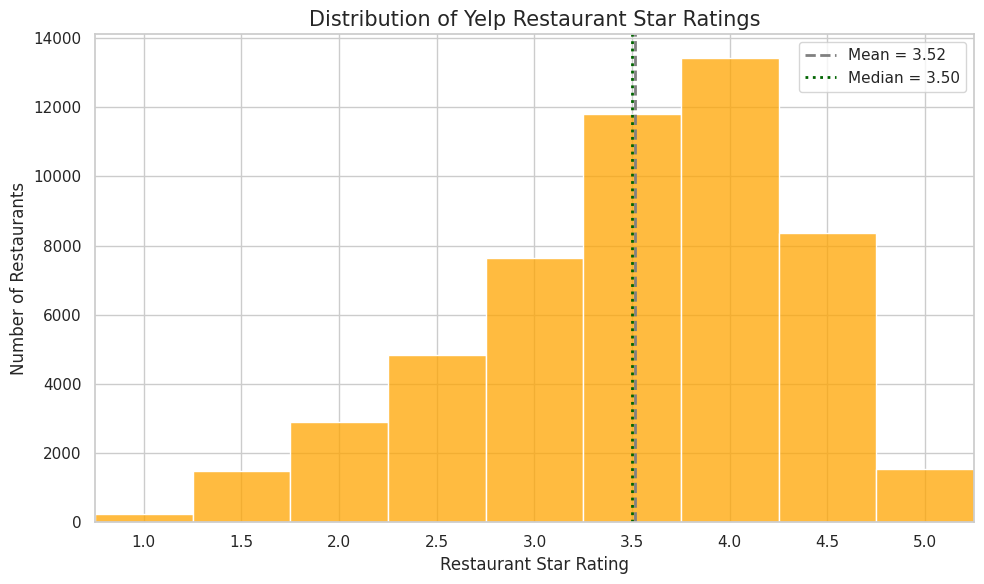

Restaurants analyzed: 52,268
Mean rating: 3.52
Median rating: 3.50
Standard deviation: 0.83


In [48]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

restaurant_ratings = yelp_restaurants["stars"].dropna()

mean_rating = restaurant_ratings.mean()
median_rating = restaurant_ratings.median()

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    restaurant_ratings,
    bins=np.arange(0.75, 5.76, 0.5),
    color="orange",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    mean_rating,
    color="gray",
    linestyle="--",
    linewidth=2,
    label=f"Mean = {mean_rating:.2f}"
)

ax.axvline(
    median_rating,
    color="darkgreen",
    linestyle=":",
    linewidth=2,
    label=f"Median = {median_rating:.2f}"
)

ax.set_title(
    "Distribution of Yelp Restaurant Star Ratings",
    fontsize=15
)
ax.set_xlabel("Restaurant Star Rating")
ax.set_ylabel("Number of Restaurants")
ax.set_xticks(np.arange(1, 5.1, 0.5))
ax.set_xlim(0.75, 5.25)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Restaurants analyzed: {len(restaurant_ratings):,}")
print(f"Mean rating: {mean_rating:.2f}")
print(f"Median rating: {median_rating:.2f}")
print(f"Standard deviation: {restaurant_ratings.std():.2f}")

##### Analysis:

By looking at this plot it could help answer how are Yelp ratings distributed among restaurants, and are ratings generally high/low/concentrated around the middle?

The ratings are centered around 3.5 stars, with most restaurants rated between 3 and 4.5 stars. Wwith a standard deviation of 0.83, the distribution is slightly left-skewed because the lower ratings stretch farther out. There are no clear outliers, and most restaurants have ratings in the middle to higher range rather than very low or perfect ratings.

#### Distribution 2: Restaurant Review Counts

Examined the number of reviews each restaurant has received on Yelp. Review counts can help show how much attention a restaurant receives from customers online. Below is histogram to visualize the distribution of review counts and included the mean and median to compare the average restaurant with the typical restaurant. This plot helps answer whether most restaurants receive a similar amount of attention or whether review activity is concentrated among a smaller number of restaurants.

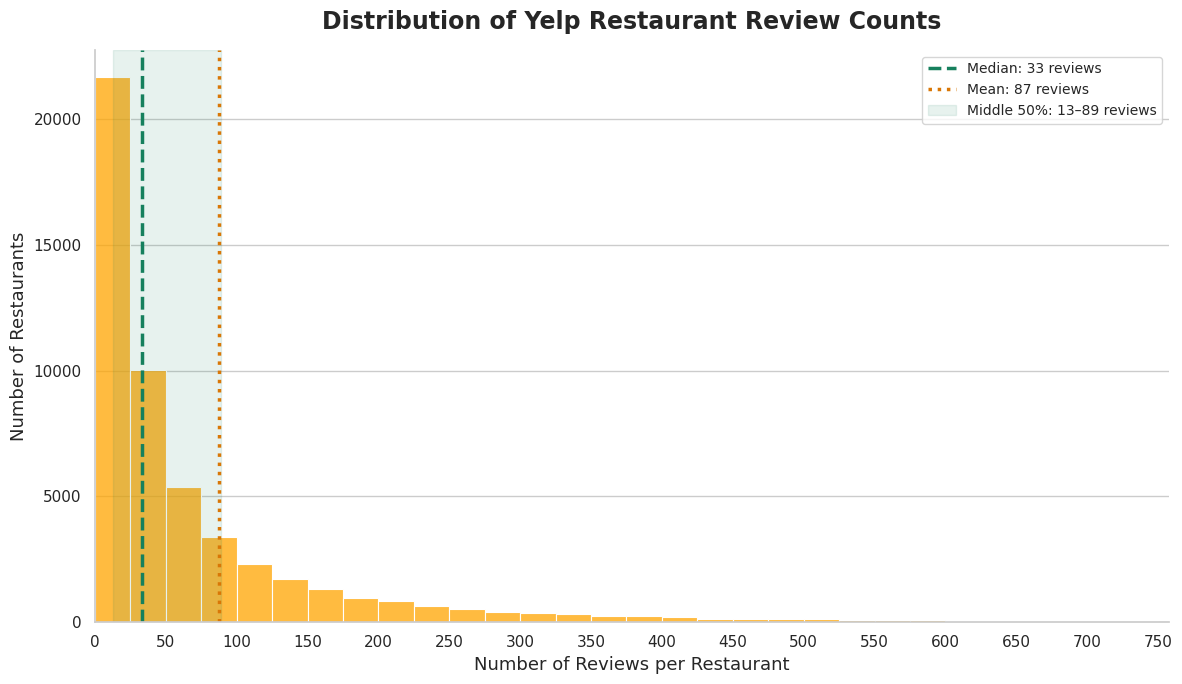

Restaurants analyzed: 52,268
Mean reviews: 87.3
Median reviews: 33.0
Standard deviation: 188.9
25th percentile: 13
75th percentile: 89
99th percentile: 758
Restaurants above plotted range: 523


In [49]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from matplotlib.ticker import MultipleLocator, StrMethodFormatter

review_counts = yelp_restaurants["review_count"].dropna()
review_counts = review_counts[review_counts > 0]
mean_reviews = review_counts.mean()
median_reviews = review_counts.median()
q1 = review_counts.quantile(0.25)
q3 = review_counts.quantile(0.75)
p99 = review_counts.quantile(0.99)

plot_counts = review_counts[review_counts <= p99]

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 7))
sns.histplot(
    plot_counts,
    bins=np.arange(0, p99 + 25, 25),
    color="orange",
    edgecolor="white",
    linewidth=0.8,
    ax=ax
)

ax.axvline(
    median_reviews,
    color="#16805D",
    linestyle="--",
    linewidth=2.5,
    label=f"Median: {median_reviews:.0f} reviews"
)

ax.axvline(
    mean_reviews,
    color="#D97706",
    linestyle=":",
    linewidth=2.5,
    label=f"Mean: {mean_reviews:.0f} reviews"
)

ax.axvspan(
    q1,
    q3,
    color="#16805D",
    alpha=0.10,
    label=f"Middle 50%: {q1:.0f}–{q3:.0f} reviews"
)

ax.set_title(
    "Distribution of Yelp Restaurant Review Counts",
    fontsize=17,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Number of Reviews per Restaurant", fontsize=13)
ax.set_ylabel("Number of Restaurants", fontsize=13)
ax.set_xlim(0, p99)
ax.xaxis.set_major_locator(MultipleLocator(50))
ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))

ax.tick_params(axis="both", labelsize=11)
ax.grid(axis="x", visible=False)
ax.legend(fontsize=10, loc="upper right")

sns.despine()
plt.tight_layout()
plt.show()

print(f"Restaurants analyzed: {len(review_counts):,}")
print(f"Mean reviews: {mean_reviews:,.1f}")
print(f"Median reviews: {median_reviews:,.1f}")
print(f"Standard deviation: {review_counts.std():,.1f}")
print(f"25th percentile: {q1:,.0f}")
print(f"75th percentile: {q3:,.0f}")
print(f"99th percentile: {p99:,.0f}")
print(f"Restaurants above plotted range: {(review_counts > p99).sum():,}")

#### Analysis of Review Count Distribution

The distribution of Yelp restaurant review counts is strongly right-skewed, meaning most restaurants have relatively few reviews while a smaller number have hundreds of reviews. The mean is approximately 87 reviews, while the median is 33 reviews, showing that restaurants with high review counts pull the average upward.

**What next?** Examine the relationship between review counts and star ratings to see whether restaurants with more reviews also tend to have higher ratings.

## Section 4. Relationships:
### Relationship Plot 1: Review characteristics and restaurant closure status

This section explores the question: **How do average rating and review volume jointly relate to whether a Chicago restaurant is marked permanently closed?**

The unit of analysis in this plot is one restaurant. Review count is also used as an indicator for establishment popularity because the Google metadata provides a status at the time when the dataset snapshot was taken but no closure date. For this reason this is a descriptive association rather than evidence that reviews cause or predict an establisments closure.

In [50]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)

# This works whether the notebook is launched from the repository root
# or from inside EDA_Checkpoint/.
data_candidates = [
    Path("data/meta-Illinois.json.gz"),
    Path("../data/meta-Illinois.json.gz"),
]
google_metadata_path = next(
    (path for path in data_candidates if path.exists()),
    None,
)

if google_metadata_path is None:
    raise FileNotFoundError(
        "Could not find data/meta-Illinois.json.gz. "
        "Place the UCSD Google Local metadata file in the repository's data folder."
    )

print(f"Using metadata file: {google_metadata_path.resolve()}")

Using metadata file: /home/hasihdsjanc/CS418_Economic_Trajectories_Group/EDA_Checkpoint/data/meta-Illinois.json.gz


In [51]:
google_metadata = pd.read_json(
    google_metadata_path,
    lines=True,
    compression="gzip",
)

print(f"Google Illinois metadata shape: {google_metadata.shape}")

Google Illinois metadata shape: (179205, 15)


### Preparation and status definition

Restaurants are identified when at least one Google category contains the word restaurant. Chicago records are identified from the city and state portion of the address. 

Duplicate gmap_id values are removed so that every business appears once.

For the outcome, **Permanently closed** is compared with nonmissing status strings that describe operating hours, such as "Open - Closes 10PM" or "Closed - Opens 11AM". Records marked **Temporarily closed** and records with missing status are excluded because they don't provide a defensible open vs. permanently-closed classification.

In [52]:
def has_restaurant_category(categories):
    return isinstance(categories, list) and any(
        "restaurant" in str(category).lower()
        for category in categories
    )

is_restaurant = google_metadata["category"].apply(has_restaurant_category)
is_chicago = google_metadata["address"].str.contains(
    r",\s*Chicago,\s*IL\b",
    case=False,
    na=False,
    regex=True,
)

chicago_restaurants = google_metadata.loc[
    is_restaurant & is_chicago
].copy()

duplicate_gmap_ids = int(chicago_restaurants.duplicated("gmap_id").sum())
chicago_restaurants = chicago_restaurants.drop_duplicates(
    subset="gmap_id",
    keep="first",
).copy()

status = chicago_restaurants["state"].astype("string").str.strip()
is_permanently_closed = status.str.casefold().eq("permanently closed").fillna(False)
is_temporarily_closed = status.str.contains(
    "temporarily closed", case=False, na=False
)
is_missing_status = status.isna() | status.eq("")
is_observed_operating = ~(
    is_permanently_closed | is_temporarily_closed | is_missing_status
)

chicago_restaurants["status_group"] = np.select(
    [
        is_permanently_closed,
        is_temporarily_closed,
        is_missing_status,
        is_observed_operating,
    ],
    [
        "Permanently closed",
        "Temporarily closed",
        "Missing status",
        "Observed operating",
    ],
    default="Unclassified",
)

status_order = [
    "Observed operating",
    "Permanently closed",
    "Temporarily closed",
    "Missing status",
]
status_audit = (
    chicago_restaurants["status_group"]
    .value_counts()
    .reindex(status_order, fill_value=0)
    .rename_axis("status_group")
    .reset_index(name="restaurants")
)

print(f"Chicago restaurant records before ID deduplication: {int((is_restaurant & is_chicago).sum()):,}")
print(f"Duplicate gmap_id rows removed: {duplicate_gmap_ids:,}")
print(f"Unique Chicago restaurants: {len(chicago_restaurants):,}")
display(status_audit)

Chicago restaurant records before ID deduplication: 8,043
Duplicate gmap_id rows removed: 9
Unique Chicago restaurants: 8,034


,status_group,restaurants
0,Observed operating,3989
1,Permanently closed,1440
2,Temporarily closed,292
3,Missing status,2313


In [53]:
analysis_restaurants = chicago_restaurants.loc[
    chicago_restaurants["status_group"].isin(
        ["Observed operating", "Permanently closed"]
    ),
    [
        "gmap_id",
        "name",
        "address",
        "avg_rating",
        "num_of_reviews",
        "status_group",
    ],
].copy()
analysis_restaurants["permanently_closed"] = (
    analysis_restaurants["status_group"] == "Permanently closed"
).astype(int)

assert not analysis_restaurants["gmap_id"].duplicated().any()
assert analysis_restaurants[["avg_rating", "num_of_reviews"]].notna().all().all()
assert analysis_restaurants["avg_rating"].between(1, 5).all()
assert analysis_restaurants["num_of_reviews"].gt(0).all()

sample_audit = pd.DataFrame(
    {
        "measure": [
            "Restaurants in analysis",
            "Observed operating",
            "Permanently closed",
            "Overall permanently closed percentage",
        ],
        "value": [
            f"{len(analysis_restaurants):,}",
            f"{(analysis_restaurants['status_group'] == 'Observed operating').sum():,}",
            f"{analysis_restaurants['permanently_closed'].sum():,}",
            f"{analysis_restaurants['permanently_closed'].mean():.1%}",
        ],
    }
)
display(sample_audit)

,measure,value
0,Restaurants in analysis,"5,429"
1,Observed operating,"3,989"
2,Permanently closed,"1,440"
3,Overall permanently closed percentage,26.5%


### Relationship: rating, review volume, and permanent closure

Review count is divided into quartiles so that each row of the heatmap has a substantial number of restaurants despite the strong right skew in review volume. Ratings are grouped into half-star-width bands. Each cell reports both the percentage marked permanently closed and the number of restaurants used to calculate that percentage. Very small cells should be interpreted cautiously.

In [54]:
rating_labels = ["<3.0", "3.0-3.4", "3.5-3.9", "4.0-4.4", "4.5-5.0"]
analysis_restaurants["rating_band"] = pd.cut(
    analysis_restaurants["avg_rating"],
    bins=[-np.inf, 3.0, 3.5, 4.0, 4.5, np.inf],
    labels=rating_labels,
    right=False,
)

quartile_labels = ["Q1", "Q2", "Q3", "Q4"]
analysis_restaurants["review_volume_quartile"] = pd.qcut(
    analysis_restaurants["num_of_reviews"],
    q=4,
    labels=quartile_labels,
)

quartile_ranges = (
    analysis_restaurants.groupby("review_volume_quartile", observed=True)["num_of_reviews"]
    .agg(minimum="min", maximum="max", restaurants="size", median="median")
)
quartile_ranges.index.name = "review-volume quartile"
display(quartile_ranges)

cell_summary = (
    analysis_restaurants.groupby(
        ["review_volume_quartile", "rating_band"],
        observed=False,
    )["permanently_closed"]
    .agg(closure_rate="mean", restaurants="size")
    .reset_index()
)

closure_rate = (
    cell_summary.pivot(
        index="review_volume_quartile",
        columns="rating_band",
        values="closure_rate",
    )
    .reindex(index=quartile_labels, columns=rating_labels)
    * 100
)
cell_counts = (
    cell_summary.pivot(
        index="review_volume_quartile",
        columns="rating_band",
        values="restaurants",
    )
    .reindex(index=quartile_labels, columns=rating_labels)
    .fillna(0)
    .astype(int)
)

annotations = closure_rate.copy().astype(object)
for row in closure_rate.index:
    for column in closure_rate.columns:
        rate = closure_rate.loc[row, column]
        count = cell_counts.loc[row, column]
        annotations.loc[row, column] = (
            f"{rate:.1f}%\n(n={count:,})" if count else "No data"
        )

quartile_closure = (
    analysis_restaurants.groupby("review_volume_quartile", observed=True)["permanently_closed"]
    .agg(restaurants="size", permanently_closed_percentage=lambda values: 100 * values.mean())
)
quartile_closure["permanently_closed_percentage"] = (
    quartile_closure["permanently_closed_percentage"].round(1)
)
display(quartile_closure)

,minimum,maximum,restaurants,median
review-volume quartile,,,,
Q1,1,46,1376,18.0
Q2,47,119,1339,77.0
Q3,121,298,1394,192.5
Q4,302,9998,1320,518.0


,restaurants,permanently_closed_percentage
review_volume_quartile,,
Q1,1376,52.0
Q2,1339,31.1
Q3,1394,15.5
Q4,1320,7.0


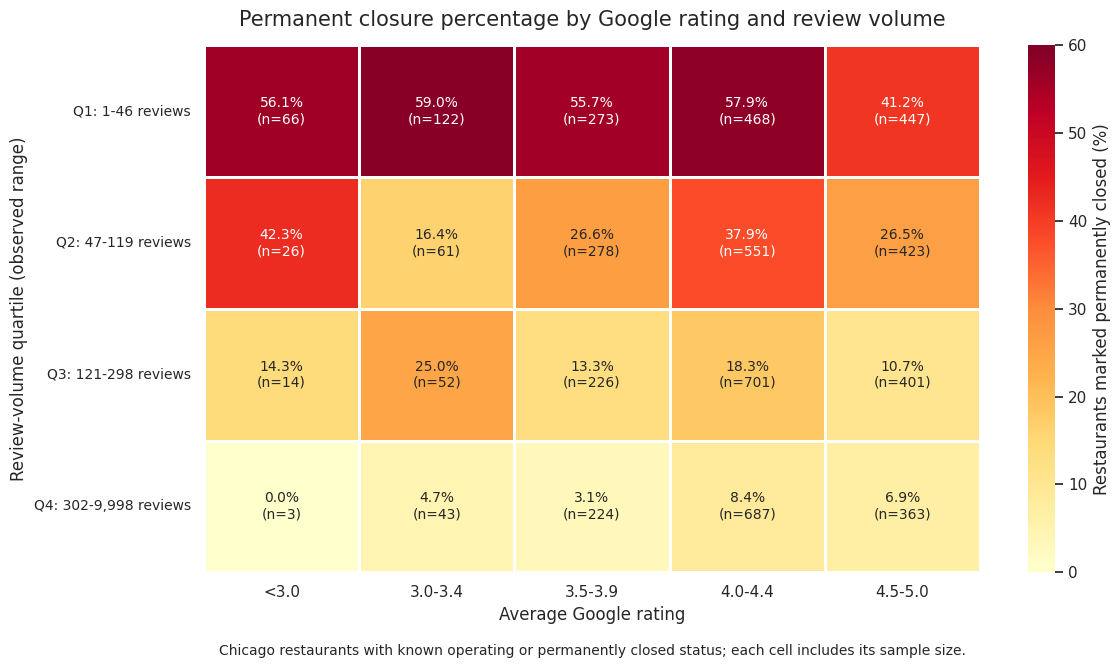

In [55]:
quartile_axis_labels = [
    f"{quartile}: {int(quartile_ranges.loc[quartile, 'minimum']):,}-"
    f"{int(quartile_ranges.loc[quartile, 'maximum']):,} reviews"
    for quartile in quartile_labels
]

fig, ax = plt.subplots(figsize=(12, 6.5))
sns.heatmap(
    closure_rate,
    annot=annotations,
    fmt="",
    cmap="YlOrRd",
    vmin=0,
    vmax=60,
    linewidths=1,
    linecolor="white",
    cbar_kws={"label": "Restaurants marked permanently closed (%)"},
    annot_kws={"fontsize": 10},
    ax=ax,
)
ax.set_title(
    "Permanent closure percentage by Google rating and review volume",
    fontsize=15,
    pad=14,
)
ax.set_xlabel("Average Google rating", fontsize=12)
ax.set_ylabel("Review-volume quartile (observed range)", fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0, fontsize=11)
ax.set_yticklabels(quartile_axis_labels, rotation=0, fontsize=10)
fig.text(
    0.5,
    -0.02,
    "Chicago restaurants with known operating or permanently closed status; each cell includes its sample size.",
    ha="center",
    fontsize=10,
)
plt.tight_layout()
plt.show()

#### Supplementary summary: review volume and permanent closure

The heatmap indicated nicely that review volume has the cleanest relationship with closure status. For this reason including a supplementary bar graph showing this relationship felt neccessary to make the overall pattern easier to compare. 

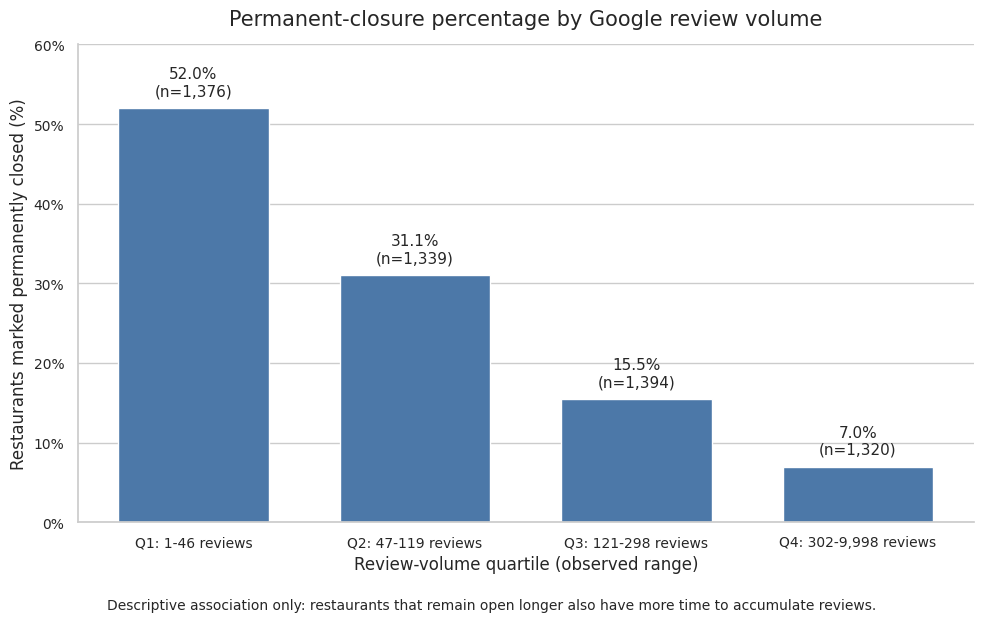

In [56]:
bar_data = quartile_closure.reset_index().copy()
bar_data["quartile_label"] = quartile_axis_labels

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.bar(
    bar_data["quartile_label"],
    bar_data["permanently_closed_percentage"],
    color="#4C78A8",
    width=0.68,
)

for bar, percentage, count in zip(
    bars,
    bar_data["permanently_closed_percentage"],
    bar_data["restaurants"],
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1.2,
        f"{percentage:.1f}%\n(n={int(count):,})",
        ha="center",
        va="bottom",
        fontsize=11,
    )

ax.set_title(
    "Permanent-closure percentage by Google review volume",
    fontsize=15,
    pad=14,
)
ax.set_xlabel("Review-volume quartile (observed range)", fontsize=12)
ax.set_ylabel("Restaurants marked permanently closed (%)", fontsize=12)
ax.set_ylim(0, 60)
ax.set_yticks(np.arange(0, 61, 10))
ax.set_yticklabels([f"{value}%" for value in range(0, 61, 10)])
ax.tick_params(axis="x", labelsize=10)
ax.tick_params(axis="y", labelsize=10)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.text(
    0.5,
    -0.03,
    "Descriptive association only: restaurants that remain open longer also have more time to accumulate reviews.",
    ha="center",
    fontsize=10,
)
plt.tight_layout()
plt.show()

### So what?

The clearest relationship is the review volume. Since we divided the review volumes into quartiles Q1, Q2, Q3, and Q4. Q1 were marked **52.0%** closed. Meaning that of the restaurants that had between 1-46 reviews on Google more than half had permenantly closed. Now compare that with only **7.0%** in Q4 (302-9,998 reviews). Moreover, restaurants with lower ratings had a closure rate. Overall: **45.9%** of restaurants rated below 3.0 out if 5.0 were marked permanently closed, compared with **22.3%** of restaurants rated 4.5-5.0. However, the rating pattern is less consistent within individual review-volume quartiles, and some low-rating cells have small sample sizes.

This relationship very important beacuse it suggest that review volume or amount is our proxy for popularity. And it may carry a stronger and more accurate relationship with operating status than average ratings alone.

This direction was expected because restaurants with more customer activity online should generally be more likely to keep their doors open. The size of the difference between Q1, lowest, and Q4, highest, review-volumes was more pronounced than we expected.

However, these results shouldn't be interpreted as a validated prediction on how an establishment will fare. Restraurants that remain open longer also have more time to accumlate reviews. Meaning, that businesses that have been established for a long time or exposure due to things like, franchises, may explain this pattern.

Google provides a snapshot status rather than a closure date, and businesses with missing or temporary status were excluded. A later predictive analysis would need time-indexed review features, a known outcome date, and controls for restaurant age, location, price, and category.

## Relationship Plot 2: Negative Google ratings and subsequent food inspection results

This section explores the question: **Do Chicago restaurants with worse food-inspection outcomes have a higher share of negative Google ratings beforehand?**

The second plot will compare primary Google Local Reviews data to the secondary Chicago Food Inspections dataset. To keep temporal order, review characteristics are calculated only from a year or 365 days before an inspection. One and two star ratings are classified as negative. Each restaurant contributes only its first qualifying inspection, and at least five years of ratings history are required.

In [57]:
import difflib
import io
import re
import time
import unicodedata
import urllib.parse
import urllib.request
from collections import defaultdict

review_candidates = [
    Path("data/review-Illinois.json.gz"),
    Path("../data/review-Illinois.json.gz"),
]
google_reviews_path = next(
    (path for path in review_candidates if path.exists()),
    None,
)
if google_reviews_path is None:
    raise FileNotFoundError(
        "Could not find data/review-Illinois.json.gz. "
        "Place the UCSD Google Local review file in the repository's data folder."
    )

inspection_endpoint = "https://data.cityofchicago.org/resource/4ijn-s7e5.csv"
dollar = chr(36)
inspection_parameters = {
    dollar + "select": (
        "inspection_id,dba_name,address,inspection_date,results,latitude,longitude"
    ),
    dollar + "where": (
        "inspection_date between '2018-01-01T00:00:00' and '2021-12-31T23:59:59' "
        "AND facility_type='Restaurant' "
        "AND results in('Pass','Pass w/ Conditions','Fail')"
    ),
    dollar + "order": "inspection_date ASC, inspection_id ASC",
    dollar + "limit": "50000",
}
inspection_url = inspection_endpoint + "?" + urllib.parse.urlencode(
    inspection_parameters
)

last_error = None
for attempt in range(3):
    try:
        with urllib.request.urlopen(inspection_url, timeout=120) as response:
            food_inspections_historical = pd.read_csv(io.BytesIO(response.read()))
        break
    except Exception as error:
        last_error = error
        if attempt == 2:
            raise
        time.sleep(2 ** attempt)

if len(food_inspections_historical) >= 50000:
    raise RuntimeError(
        "The inspection query reached its 50,000-row limit; pagination is required."
    )

food_inspections_historical["inspection_date"] = pd.to_datetime(
    food_inspections_historical["inspection_date"],
    errors="coerce",
)
food_inspections_historical = food_inspections_historical.dropna(
    subset=["inspection_date", "latitude", "longitude", "dba_name"]
).copy()
food_inspections_historical = food_inspections_historical.loc[
    food_inspections_historical["latitude"].between(41.60, 42.10)
    & food_inspections_historical["longitude"].between(-87.95, -87.50)
].copy()

print(f"Historical restaurant inspections retrieved: {len(food_inspections_historical):,}")
print(
    "Inspection date range:",
    food_inspections_historical["inspection_date"].min().date(),
    "to",
    food_inspections_historical["inspection_date"].max().date(),
)
display(
    food_inspections_historical["results"]
    .value_counts()
    .rename_axis("inspection result")
    .reset_index(name="inspections")
)

Historical restaurant inspections retrieved: 38,360
Inspection date range: 2018-01-02 to 2021-12-30


,inspection result,inspections
0,Pass,15351
1,Pass w/ Conditions,14563
2,Fail,8446


### Restaurant linkage

This potential linkage error has to be mentioned. Since these two datasets dont share a common business ID, restraurants are therefore generated from neighboring latitude and longitude grid cells and found using exact geograpic data and business name and street number used as a backup ID. This is the reason for the extra code below.

A match is only accepted when either name similarity is at least 0.80 within 60 meters, or the street number agrees within 40 meters and the names have some moderate similarity. This allows for only the best candidate being retained for each inspection reducing false matches while allowing things like abbreviations.

In [58]:
def normalize_business_name(value):
    normalized = (
        unicodedata.normalize("NFKD", str(value))
        .encode("ascii", "ignore")
        .decode()
    )
    normalized = re.sub(r"[^a-z0-9 ]+", " ", normalized.lower())
    normalized = re.sub(
        r"\b(inc|llc|corp|corporation|company|co|restaurant|restaurants|the)\b",
        " ",
        normalized,
    )
    return " ".join(normalized.split())


def extract_street_number(value):
    match = re.search(r"\b(\d+)\b", str(value))
    return match.group(1) if match else None


def haversine_distance_m(lat1, lon1, lat2, lon2):
    radius_m = 6_371_000.0
    phi1 = np.radians(lat1)
    phi2 = np.radians(lat2)
    delta_phi = np.radians(lat2 - lat1)
    delta_lambda = np.radians(lon2 - lon1)
    haversine = (
        np.sin(delta_phi / 2) ** 2
        + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2) ** 2
    )
    return 2 * radius_m * np.arcsin(np.sqrt(haversine))


google_match_table = chicago_restaurants[
    ["gmap_id", "name", "address", "latitude", "longitude"]
].dropna(subset=["latitude", "longitude"]).copy()
google_match_table["normalized_name"] = google_match_table["name"].map(
    normalize_business_name
)
google_match_table["street_number"] = google_match_table["address"].map(
    extract_street_number
)
google_match_table["grid_lat"] = np.floor(
    google_match_table["latitude"] * 1000
).astype(int)
google_match_table["grid_lon"] = np.floor(
    google_match_table["longitude"] * 1000
).astype(int)

inspection_match_table = food_inspections_historical.copy()
inspection_match_table["normalized_name"] = inspection_match_table["dba_name"].map(
    normalize_business_name
)
inspection_match_table["street_number"] = inspection_match_table["address"].map(
    extract_street_number
)
inspection_match_table["grid_lat"] = np.floor(
    inspection_match_table["latitude"] * 1000
).astype(int)
inspection_match_table["grid_lon"] = np.floor(
    inspection_match_table["longitude"] * 1000
).astype(int)

spatial_grid = defaultdict(list)
for google_index, google_row in google_match_table.iterrows():
    spatial_grid[(google_row.grid_lat, google_row.grid_lon)].append(google_index)

candidate_matches = []
for inspection in inspection_match_table.itertuples(index=False):
    candidate_indices = []
    for latitude_offset in (-1, 0, 1):
        for longitude_offset in (-1, 0, 1):
            candidate_indices.extend(
                spatial_grid.get(
                    (
                        inspection.grid_lat + latitude_offset,
                        inspection.grid_lon + longitude_offset,
                    ),
                    [],
                )
            )
    if not candidate_indices:
        continue

    nearby_google = google_match_table.loc[candidate_indices]
    distances = haversine_distance_m(
        inspection.latitude,
        inspection.longitude,
        nearby_google["latitude"].to_numpy(),
        nearby_google["longitude"].to_numpy(),
    )

    for google_index, distance_m in zip(nearby_google.index, distances):
        if distance_m > 60:
            continue
        google_candidate = google_match_table.loc[google_index]
        name_similarity = difflib.SequenceMatcher(
            None,
            inspection.normalized_name,
            google_candidate.normalized_name,
        ).ratio()
        same_street_number = bool(
            inspection.street_number
            and google_candidate.street_number
            and inspection.street_number == google_candidate.street_number
        )
        name_containment = bool(
            min(
                len(inspection.normalized_name),
                len(google_candidate.normalized_name),
            )
            >= 4
            and (
                inspection.normalized_name in google_candidate.normalized_name
                or google_candidate.normalized_name in inspection.normalized_name
            )
        )
        strong_name_match = name_similarity >= 0.80 and distance_m <= 60
        address_supported_match = (
            distance_m <= 40
            and same_street_number
            and (name_similarity >= 0.55 or name_containment)
        )
        if strong_name_match or address_supported_match:
            candidate_matches.append(
                {
                    "inspection_id": inspection.inspection_id,
                    "inspection_name": inspection.dba_name,
                    "inspection_date": inspection.inspection_date,
                    "results": inspection.results,
                    "gmap_id": google_candidate.gmap_id,
                    "google_name": google_candidate["name"],
                    "distance_m": float(distance_m),
                    "name_similarity": name_similarity,
                    "match_score": name_similarity - float(distance_m) / 1000,
                }
            )

matched_inspections = pd.DataFrame(candidate_matches)
matched_inspections = (
    matched_inspections.sort_values(
        ["inspection_id", "match_score"],
        ascending=[True, False],
    )
    .drop_duplicates("inspection_id")
    .reset_index(drop=True)
)

match_audit = pd.DataFrame(
    {
        "measure": [
            "Historical inspections retrieved",
            "Inspections linked to Google restaurants",
            "Unique linked Google restaurants",
            "Median link distance (meters)",
            "Median name similarity",
        ],
        "value": [
            f"{len(food_inspections_historical):,}",
            f"{len(matched_inspections):,}",
            f"{matched_inspections['gmap_id'].nunique():,}",
            f"{matched_inspections['distance_m'].median():.1f}",
            f"{matched_inspections['name_similarity'].median():.2f}",
        ],
    }
)
display(match_audit)
display(
    matched_inspections.sample(8, random_state=418)[
        [
            "inspection_name",
            "google_name",
            "distance_m",
            "name_similarity",
            "results",
        ]
    ].round({"distance_m": 1, "name_similarity": 2})
)

,measure,value
0,Historical inspections retrieved,"38,360"
1,Inspections linked to Google restaurants,"22,831"
2,Unique linked Google restaurants,"5,182"
3,Median link distance (meters),13.9
4,Median name similarity,1.00


,inspection_name,google_name,distance_m,name_similarity,results
2802,EL POLLO REAL,El Pollo Real,7.3,1.00,Pass w/ Conditions
471,DE ARCOS PIZZA & RESTAURANT,De Arcos Pizza,16.2,1.00,Fail
19788,El Gran Burrito Express,El Gran Burrito Express,14.2,1.00,Pass w/ Conditions
453,SARPINOS PIZZERIA,Sarpino's Pizzeria,16.9,0.97,Fail
16512,TACO BELL,Taco Bell,35.5,1.00,Pass w/ Conditions
12183,CELESTE,Celeste,4.1,1.00,Pass
10785,EL ALEGRE BURRITO,El Alegre Burrito (Chicago),16.7,0.81,Pass w/ Conditions
6621,TAQUERIA EL CHARRO,Taquería El Charro I,16.5,0.95,Pass w/ Conditions


### Constructing prior-review features

The Illinois review archive is streamed rather than loaded fully into memory. Only ratings and timestamps that can be linked to Chicago restaurants are retained. For every inspection, the negative reviews shared is calculated from ratings posted with in the 365 days. Datapoints with fewer than five ratings are removed. Also earliest inspection is selected for each restaurant so that businesses that get more inspections in the same amount of time due to their type (seafood restraunts) dont saturate the comparison.

In [59]:
target_gmap_ids = set(matched_inspections["gmap_id"])
reviews_by_business = defaultdict(list)
total_review_rows = 0
retained_review_rows = 0
scan_started = time.time()

with gzip.open(google_reviews_path, "rt", encoding="utf-8") as review_file:
    for line in review_file:
        total_review_rows += 1
        review = json.loads(line)
        gmap_id = review.get("gmap_id")
        if gmap_id in target_gmap_ids:
            rating = review.get("rating")
            timestamp = review.get("time")
            if isinstance(rating, (int, float)) and isinstance(timestamp, (int, float)):
                reviews_by_business[gmap_id].append(
                    (int(timestamp), float(rating))
                )
                retained_review_rows += 1
        if total_review_rows % 5_000_000 == 0:
            print(
                f"Scanned {total_review_rows:,} reviews; "
                f"retained {retained_review_rows:,}."
            )

review_arrays = {}
for gmap_id, values in reviews_by_business.items():
    values.sort(key=lambda item: item[0])
    review_arrays[gmap_id] = (
        np.array([item[0] for item in values], dtype=np.int64),
        np.array([item[1] for item in values], dtype=float),
    )
del reviews_by_business

print(f"Total Illinois review rows scanned: {total_review_rows:,}")
print(f"Ratings retained for linked restaurants: {retained_review_rows:,}")
print(f"Review scan time: {time.time() - scan_started:.1f} seconds")

Scanned 5,000,000 reviews; retained 194,780.
Scanned 10,000,000 reviews; retained 589,414.
Scanned 15,000,000 reviews; retained 1,153,017.
Scanned 20,000,000 reviews; retained 1,684,547.
Total Illinois review rows scanned: 23,096,838
Ratings retained for linked restaurants: 2,159,585
Review scan time: 114.1 seconds


In [60]:
inspection_events = []
one_year_ms = 365 * 24 * 60 * 60 * 1000

for inspection in matched_inspections.sort_values(
    ["gmap_id", "inspection_date"]
).itertuples(index=False):
    if inspection.gmap_id not in review_arrays:
        continue
    review_times, review_ratings = review_arrays[inspection.gmap_id]
    inspection_time_ms = int(inspection.inspection_date.value // 1_000_000)
    window_start = np.searchsorted(
        review_times, inspection_time_ms - one_year_ms, side="left"
    )
    window_end = np.searchsorted(
        review_times, inspection_time_ms, side="left"
    )
    prior_ratings = review_ratings[window_start:window_end]
    if len(prior_ratings) < 5:
        continue
    inspection_events.append(
        {
            "gmap_id": inspection.gmap_id,
            "inspection_id": inspection.inspection_id,
            "inspection_date": inspection.inspection_date,
            "results": inspection.results,
            "prior_review_count": len(prior_ratings),
            "negative_review_share": float(np.mean(prior_ratings <= 2)),
            "prior_average_rating": float(np.mean(prior_ratings)),
        }
    )

inspection_events = pd.DataFrame(inspection_events)
inspection_events = (
    inspection_events.sort_values(["gmap_id", "inspection_date"])
    .drop_duplicates("gmap_id", keep="first")
    .reset_index(drop=True)
)
result_order = ["Pass", "Pass w/ Conditions", "Fail"]
inspection_events["results"] = pd.Categorical(
    inspection_events["results"],
    categories=result_order,
    ordered=True,
)
inspection_events["negative_review_percentage"] = (
    100 * inspection_events["negative_review_share"]
)

inspection_summary = (
    inspection_events.groupby("results", observed=True)
    .agg(
        restaurants=("gmap_id", "size"),
        mean_negative_percentage=("negative_review_percentage", "mean"),
        median_negative_percentage=("negative_review_percentage", "median"),
        first_quartile=("negative_review_percentage", lambda values: values.quantile(0.25)),
        third_quartile=("negative_review_percentage", lambda values: values.quantile(0.75)),
    )
    .reindex(result_order)
)
inspection_summary[[
    "mean_negative_percentage",
    "median_negative_percentage",
    "first_quartile",
    "third_quartile",
]] = inspection_summary[[
    "mean_negative_percentage",
    "median_negative_percentage",
    "first_quartile",
    "third_quartile",
]].round(1)
inspection_summary.index.name = "inspection result"
display(inspection_summary)
print(
    f"Final one-event-per-restaurant analysis sample: "
    f"{len(inspection_events):,} restaurants"
)

,restaurants,mean_negative_percentage,median_negative_percentage,first_quartile,third_quartile
inspection result,,,,,
Pass,1482,10.6,7.9,3.7,14.3
Pass w/ Conditions,2110,11.1,7.9,4.0,15.3
Fail,1246,12.5,9.1,4.9,17.3


Final one-event-per-restaurant analysis sample: 4,838 restaurants


### Relationship: prior negative ratings across inspection outcomes

The box plot compares the distribution of prior negative Google ratings and inspection outcomes.

/tmp/ipykernel_10633/4173797873.py:28: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


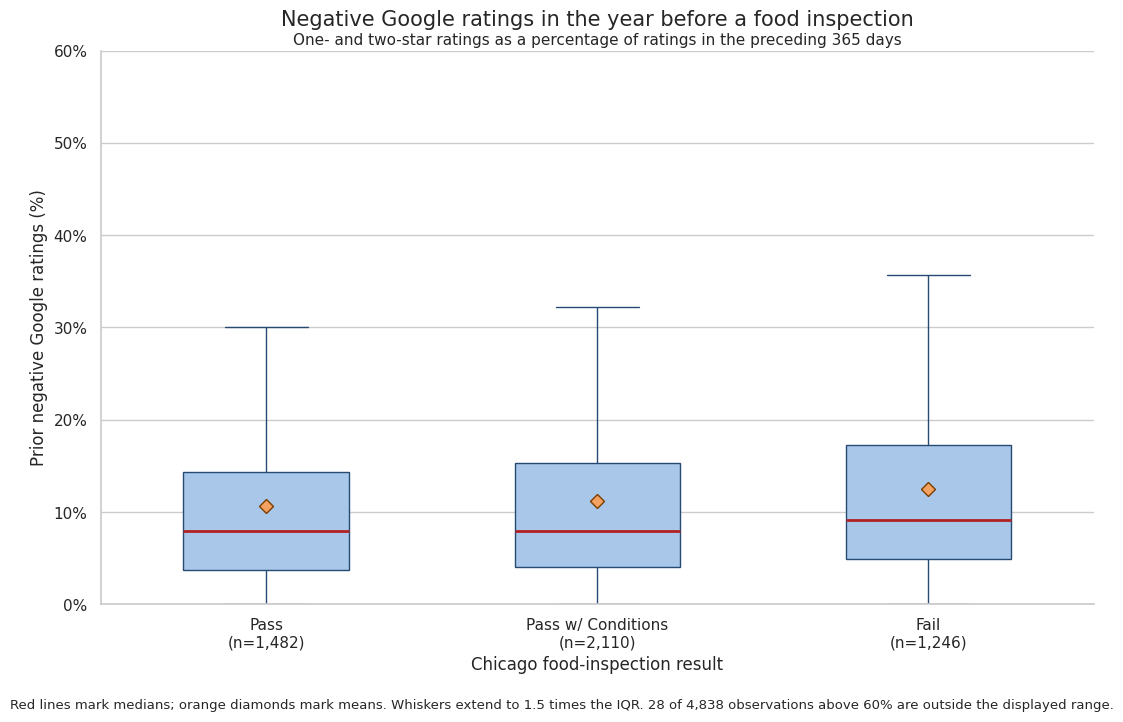

In [61]:
above_display_range = int(
    (inspection_events["negative_review_percentage"] > 60).sum()
)

fig, ax = plt.subplots(figsize=(11, 7))
sns.boxplot(
    data=inspection_events,
    x="results",
    y="negative_review_percentage",
    order=result_order,
    width=0.5,
    showfliers=False,
    showmeans=True,
    boxprops={"facecolor": "#A9C7E8", "edgecolor": "#264B73"},
    medianprops={"color": "#B22222", "linewidth": 2},
    whiskerprops={"color": "#264B73"},
    capprops={"color": "#264B73"},
    meanprops={
        "marker": "D",
        "markerfacecolor": "#F4A261",
        "markeredgecolor": "#7A3E00",
        "markersize": 7,
    },
    ax=ax,
)

sample_sizes = inspection_summary["restaurants"].astype(int).to_dict()
ax.set_xticklabels(
    [f"{result}\n(n={sample_sizes[result]:,})" for result in result_order],
    fontsize=11,
)
ax.set_title(
    "Negative Google ratings in the year before a food inspection",
    fontsize=15,
    pad=18,
)
ax.text(
    0.5,
    1.01,
    "One- and two-star ratings as a percentage of ratings in the preceding 365 days",
    transform=ax.transAxes,
    ha="center",
    fontsize=11,
)
ax.set_xlabel("Chicago food-inspection result", fontsize=12)
ax.set_ylabel("Prior negative Google ratings (%)", fontsize=12)
ax.set_ylim(0, 60)
ax.set_yticks(np.arange(0, 61, 10))
ax.set_yticklabels([f"{value}%" for value in range(0, 61, 10)])
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.text(
    0.5,
    -0.025,
    (
        "Red lines mark medians; orange diamonds mark means. Whiskers extend to 1.5 times the IQR. "
        f"{above_display_range:,} of {len(inspection_events):,} observations above 60% are outside the displayed range."
    ),
    ha="center",
    fontsize=9.5,
)
plt.tight_layout()
plt.show()

### So what?

With this box-plot were able observe that restaurants that failed an inspection had a slightly higher share of negative Google ratings during the preceding year. The failed group averaged **12.5%** negative ratings with a **9.1%** median, compared with **10.6%** and **7.9%** among restaurants that passed. Restaurants passing with conditions fell between them by mean **11.1%** and had a median of **7.9%**. All three distributions are right-skewed and overlap substantially.

This result was expected because poor restaurant cleanliness, food handling, and service condtions could affect both customer ratings and the afformentioned health inspections by Chicago authorities. However, the size of the differences were smaller than expected.

Failed inspections were only associated with only about 1.9 percentage points more negative ratins on average than a passing result. This suggests that ratings online may contain valid signals about an establisment's operational problems but are not strong enough to stand alone as an inspection to risk indicator. Written reviews mentioning these operational problems regaring cleanliness or safety maybe more accurate than star or numeric ratings alone.

This is an association, not evidence that negative reviews cause a direct inspection failiure. Things like restaurant type, location, price, review amount and inspection categories could affect both of these variables. Also linkage error could be very unlikely but possible beacuse Google and Chicago food-inspections lack a common identifier for each establisment, but since geograpic and name variables vere used as thresholds the linkage is error is very unlikely.



## Relationship Plot 3: Food-inspection results and later permanent closure

This section explores the question: **Are Chicago restaurants that fail a food inspection more likely to be marked permanently closed later, and does review volume change that pattern?**

This plot joins the two earlier analyses. Each restaurant's first qualifying inspection result (Plot 2) is linked by `gmap_id` to its Google status (Plot 1). Because the inspection happened while the restaurant was operating, the closure status comes later in time. Restaurants are also split at the median Google review count, since Plot 1 showed review volume is strongly related to closure. Only restaurants with a known "Observed operating" or "Permanently closed" status are included.

Inspected restaurants (Plot 2 sample): 4,838
With known open/permanently closed status: 3,251


,closure_pct,n
results,,
Pass,15.7,944
Pass w/ Conditions,12.2,1447
Fail,16.4,860


,results,volume_group,closure_pct,n
0,Pass,Above median,7.3,466
1,Pass,At or below median (188 reviews),23.8,478
2,Pass w/ Conditions,Above median,5.4,717
3,Pass w/ Conditions,At or below median (188 reviews),18.8,730
4,Fail,Above median,8.0,436
5,Fail,At or below median (188 reviews),25.0,424


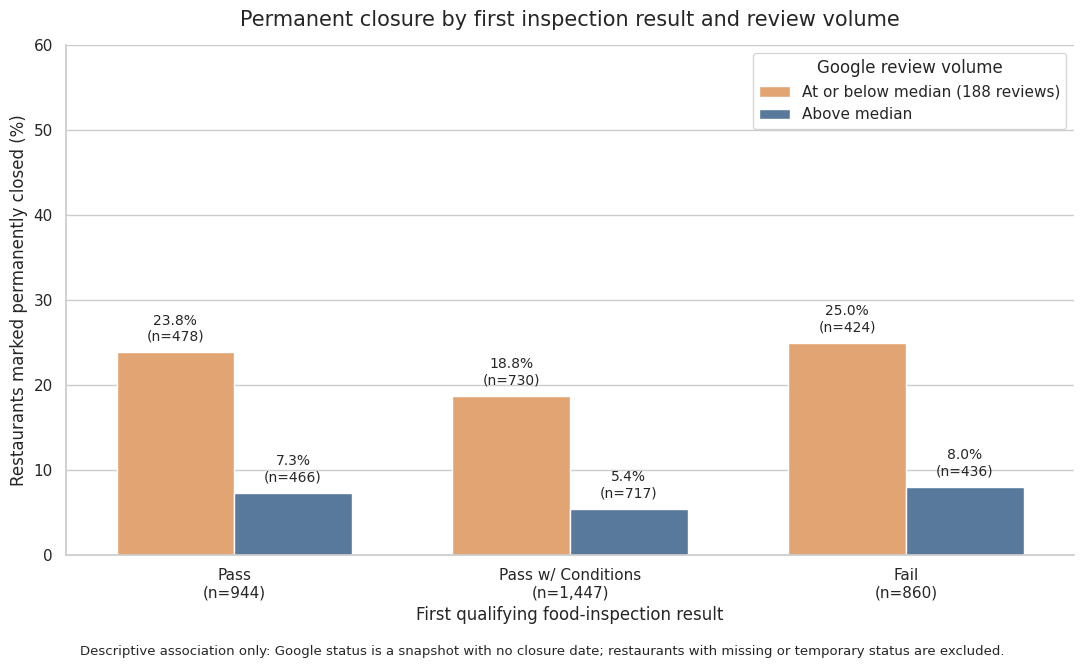

In [62]:
plot3 = inspection_events.merge(
    analysis_restaurants[["gmap_id", "permanently_closed", "num_of_reviews"]],
    on="gmap_id",
    how="inner",
)
plot3["results"] = pd.Categorical(plot3["results"], categories=result_order, ordered=True)

print(f"Inspected restaurants (Plot 2 sample): {len(inspection_events):,}")
print(f"With known open/permanently closed status: {len(plot3):,}")

median_reviews_p3 = plot3["num_of_reviews"].median()
low_label = f"At or below median ({median_reviews_p3:.0f} reviews)"
high_label = "Above median"
plot3["volume_group"] = np.where(
    plot3["num_of_reviews"] <= median_reviews_p3, low_label, high_label
)

summary3 = (
    plot3.groupby(["results", "volume_group"], observed=True)["permanently_closed"]
    .agg(closure_pct=lambda s: 100 * s.mean(), n="size")
    .reset_index()
)
overall3 = (
    plot3.groupby("results", observed=True)["permanently_closed"]
    .agg(closure_pct=lambda s: round(100 * s.mean(), 1), n="size")
    .reindex(result_order)
)
display(overall3)
display(summary3.round(1))

lookup = summary3.set_index(["results", "volume_group"])
hue_order = [low_label, high_label]

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.barplot(
    data=summary3, x="results", y="closure_pct", hue="volume_group",
    order=result_order, hue_order=hue_order,
    palette=["#F4A261", "#4C78A8"], width=0.7, ax=ax,
)
for container, group in zip(ax.containers, hue_order):
    for bar, result in zip(container, result_order):
        if (result, group) in lookup.index:
            row = lookup.loc[(result, group)]
            ax.text(
                bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 1,
                f"{row['closure_pct']:.1f}%\n(n={int(row['n']):,})",
                ha="center", va="bottom", fontsize=10,
            )

ax.set_xticks(range(len(result_order)))
ax.set_xticklabels(
    [f"{r}\n(n={int(overall3.loc[r, 'n']):,})" for r in result_order], fontsize=11
)
ax.set_title("Permanent closure by first inspection result and review volume", fontsize=15, pad=14)
ax.set_xlabel("First qualifying food-inspection result", fontsize=12)
ax.set_ylabel("Restaurants marked permanently closed (%)", fontsize=12)
ax.set_ylim(0, 60)
ax.legend(title="Google review volume")
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)
fig.text(
    0.5, -0.02,
    "Descriptive association only: Google status is a snapshot with no closure date; restaurants with missing or temporary status are excluded.",
    ha="center", fontsize=9.5,
)
plt.tight_layout()
plt.show()

### So what?

Restaurants that failed their first inspection were marked permanently closed **16.4%** of the time, compared with **15.7%** of those that passed and **12.2%** of those that passed with conditions. That is a gap of only 0.7 percentage points between pass and fail, and the pass-with-conditions group had the lowest closure rate of the three. Review volume separates restaurants far more clearly. Restaurants at or below the median of 188 Google reviews closed more often than those above it in every inspection group (**25.0%** vs. **8.0%** for failures, 23.8% vs. 7.3% for passes, and 18.8% vs. 5.4% for passes with conditions).

This was somewhat unexpected. A failed inspection suggests operational problems, so a clearly higher closure rate seemed plausible, but the pass-fail difference was much smaller than expected. It is also far smaller than the review-volume gap from Plot 1 (52.0% vs. 7.0%). Together with Plot 2, where failed inspections were associated with only about 1.9 percentage points more negative ratings, this suggests that inspection outcomes are a weak signal of closure compared with review volume.

This is an association only. Google gives a snapshot status with no closure date, so we cannot say how long after the inspection a restaurant closed, and 2020 pandemic closures likely affect every group. A restaurant that was relocated or renamed may also be marked permanently closed. The sample has limits too. Of the 4,838 restaurants from Plot 2, only 3,251 have a known open or permanently closed status, and all of them had at least five Google ratings in the year before inspection. This leans toward more active restaurants, which is why the overall closure rate here is well below the 26.5% in Plot 1.

## 6. What next?

### Plot 1 (rating, review volume, and permanent closure)
**Next question:** Does review volume still predict closure once restaurant age is held constant?
Plot 1 showed a gap of 52.0% closed in Q1 vs. 7.0% in Q4, but older restaurants have had more time to collect reviews. The Chicago Business Licenses dataset (already loaded) has license dates that could give each restaurant an age and a rough closure date, though only 50,000 rows were pulled so coverage needs checking. I would also split by cuisine/category and by chain vs. independent, since chains may drive high review counts.

### Plot 2 (negative ratings before inspections)
**Next question:** Do the written reviews carry a signal that star ratings miss?
The failed group averaged only about 1.9 percentage points more negative ratings than the passed group (12.5% vs. 10.6%). I would pull review text from the same 365-day window and test for cleanliness and food-safety terms by inspection outcome. I would also split by inspection risk level, and check whether the five-rating minimum filtered the sample toward popular restaurants. A hand-check of a random sample of linked records would validate the matching.

### Plot 3 (inspection results and later closure)
**Next question:** Does inspection severity or timing explain closure better than a simple pass/fail label?
Failed restaurants closed only slightly more often than passed ones (16.4% vs. 15.7%), so pass/fail may be too coarse. I would look at the number and type of violations, the facility risk level, and repeat failures. I would also split by inspection year (2018-2019 vs. 2020-2021) to separate pandemic-era closures from earlier ones, and use license dates to estimate how long after an inspection closures happen. A national Yelp `is_open` check could test whether the review-volume pattern holds on another platform, though Yelp has only one Chicago business in this dataset.

### Research questions, restated

**Current questions:**
1. How do average rating and review volume relate to whether a Chicago restaurant is permanently closed?
2. Do Chicago restaurants with worse food-inspection outcomes have a higher share of negative Google ratings beforehand?

**Revised questions:**
1. Is review volume still associated with permanent closure after accounting for restaurant age, category, and chain status?
2. Do the content of written reviews, not just star ratings, signal worse inspection outcomes?
3. Do more detailed inspection measures (violation severity, risk level, repeat failures) help explain permanent closure beyond review volume?

**What changed and why:**
- **Question 1 now requires control for age.** Review volume was the strongest signal in Plots 1 and 3, but restaurant age is the most likely explanation, and the licenses data can address it.
- **Question 2 now includes review text.** The star-rating difference was small, so the written reviews are the better next signal.
- **Question 3 is new and narrower than expected.** Plot 3 showed that a simple pass/fail result barely relates to closure (16.4% vs. 15.7%), so the next step is to test whether finer-grained inspection details carry any signal that pass/fail hides.